## Multiclass labels division
- Ischemic heart disease : {"I20", "I21", "I22", "I24", "I25"}
- Arrhythmias, conduction disorders and cardiac arrest: {"I44", "I45", "I46", "I47", "I48", "I49"},         
- Valvular and pump failure disorders: {"I34", "I35", "I36", "I50", "I42"},              
- Inflammatory and structural heart disease: {"I30", "I31", "I33", "I40"}

Multiclass labels were generated using a clinically motivated priority rule.
When a subject presents ICD codes belonging to multiple cardiovascular categories,
a single class is assigned according to a predefined severity hierarchy ( Ischemic > Arrhythmias > Valvular/Pump failure > Inflammatory).


In [1]:
# Optional Task: Multiclass Classification

import sys
import os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd

from labels_multiclass_classification import generate_multiclass_labels

PROFILE_PATH = "../../data/profiles/patient_profile.csv"
DIAG_PATH = "../../data/raw/heart_diagnoses_1.csv"
LABELS_OUT = "../../data/processed/subject_to_labels_multiclass.csv"

# Load patient profile
df = pd.read_csv(PROFILE_PATH)
df["subject_id"] = df["subject_id"].astype(str)

print("Patient profile loaded:", df.shape)

# Generate multiclass labels (analogous to binary task)
labels_df = generate_multiclass_labels(
    diagnoses_path=DIAG_PATH,
    output_path=LABELS_OUT
)

print("Multiclass labels generated:")
print(
    labels_df["label_multiclass"]
    .value_counts()
    .sort_index()
)

# Merge features + labels
clf_df = df.merge(labels_df, on="subject_id", how="inner")

# Remove ICD-derived features to avoid data leakage
ICD_MACRO_COLS = [
    "ACS_acute_ischemic",
    "Chronic_ischemic",
    "Heart_failure",
    "Valvular_nonrheumatic",
    "Myocarditis_or_cardiomyopathy",
    "Pericardial_disease",
    "Endocarditis",
    "Cardiac_arrest",
    "Arrhythmias_or_conduction",
]

clf_df = clf_df.drop(columns=[c for c in ICD_MACRO_COLS if c in clf_df.columns])

print("Final multiclass classification dataset:", clf_df.shape)
clf_df.head()


Patient profile loaded: (4384, 36)
Multiclass labels generated:
label_multiclass
0    2018
1     651
2    1454
3     269
Name: count, dtype: int64
Final multiclass classification dataset: (4384, 28)


,subject_id,number_of_hadm,gender,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,...,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio,label_multiclass
0,10000980,2,1,75,169.0,1.0,0.0,0.0,7.0,3.100000,...,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284,0
1,10002013,1,1,69,40.0,0.0,0.0,0.0,2.0,10.833333,...,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000,0
2,10002155,1,1,69,287.0,4.0,0.0,0.0,8.0,2.000000,...,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760,0
3,10004457,1,0,66,21.0,0.0,0.0,0.0,0.0,0.733333,...,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333,2
4,10007058,1,0,48,112.0,2.0,0.0,0.0,2.0,1.366667,...,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000,0


## Multinomial Logistic Regression
For the optional multiclass task, we adopted a Multinomial Logistic Regression model. The model directly optimizes the categorical cross-entropy loss through a softmax function, allowing the simultaneous modeling of all classes.

Given the strong class imbalance (in particular for the inflammatory category), a class-balanced loss was used to prevent the majority classes from dominating the optimization process.

Feature standardization was applied to ensure numerical stability and proper regularization behavior.

The use of a stratified train/test split guarantees that all diagnostic categories are represented in both sets.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Train / Test split (stratified)

TARGET = "label_multiclass"
ID_COL = "subject_id"

X = clf_df.drop(columns=[TARGET, ID_COL])
y = clf_df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,          # fondamental for class balance
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("\nTrain label distribution:")
print(
    y_train
    .value_counts(normalize=True)
    .sort_index()
)



Train shape: (3068, 26)
Test shape : (1316, 26)

Train label distribution:
label_multiclass
0    0.460235
1    0.147979
2    0.330834
3    0.060952
Name: proportion, dtype: float64


The stratified train/test split preserves the original class distribution. As expected, the multiclass problem is strongly imbalanced, with ischemic heart disease representing the majority class and inflammatory/structural conditions being relatively rare.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

mlr_clf = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        multi_class="multinomial",   # softmax (categorical cross-entropy)
        solver="lbfgs",              
        penalty="l2",                # ridge regularization 
        C=1.0,
        class_weight="balanced",     
        max_iter=3000,
        random_state=42
    ))
])

mlr_clf.fit(X_train, y_train)


/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [4]:
#evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score
)

y_train_pred = mlr_clf.predict(X_train)
y_test_pred = mlr_clf.predict(X_test)

print("\nBalanced accuracy (train):",
      balanced_accuracy_score(y_train, y_train_pred))
print("Balanced accuracy (test): ",
      balanced_accuracy_score(y_test, y_test_pred))

print("\nClassification report (test):")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=[
        "Ischemic",
        "Arrhythmias",
        "Valvular / Pump failure",
        "Inflammatory / Structural"
    ]
))



Balanced accuracy (train): 0.6963040159681082
Balanced accuracy (test):  0.6840692978784306

Classification report (test):
                           precision    recall  f1-score   support

                 Ischemic       0.88      0.64      0.74       606
              Arrhythmias       0.33      0.52      0.40       194
  Valvular / Pump failure       0.74      0.68      0.71       436
Inflammatory / Structural       0.43      0.90      0.58        80

                 accuracy                           0.65      1316
                macro avg       0.59      0.68      0.61      1316
             weighted avg       0.72      0.65      0.67      1316



The multinomial logistic regression model achieves a balanced accuracy of approximately 0.68 on the test set,
indicating stable and consistent performance across the four diagnostic categories.

The model shows strong precision for ischemic heart disease and valvular/pump failure disorders,
while arrhythmias present higher confusion due to overlapping clinical patterns.
Importantly, the inflammatory/structural class, although rare, is identified with very high recall,
reflecting the effect of class-balanced loss and aligning with clinical priorities.

Overall, the results confirm that multinomial logistic regression provides a reasonable and interpretable
baseline for the multiclass cardiovascular classification task under severe class imbalance.


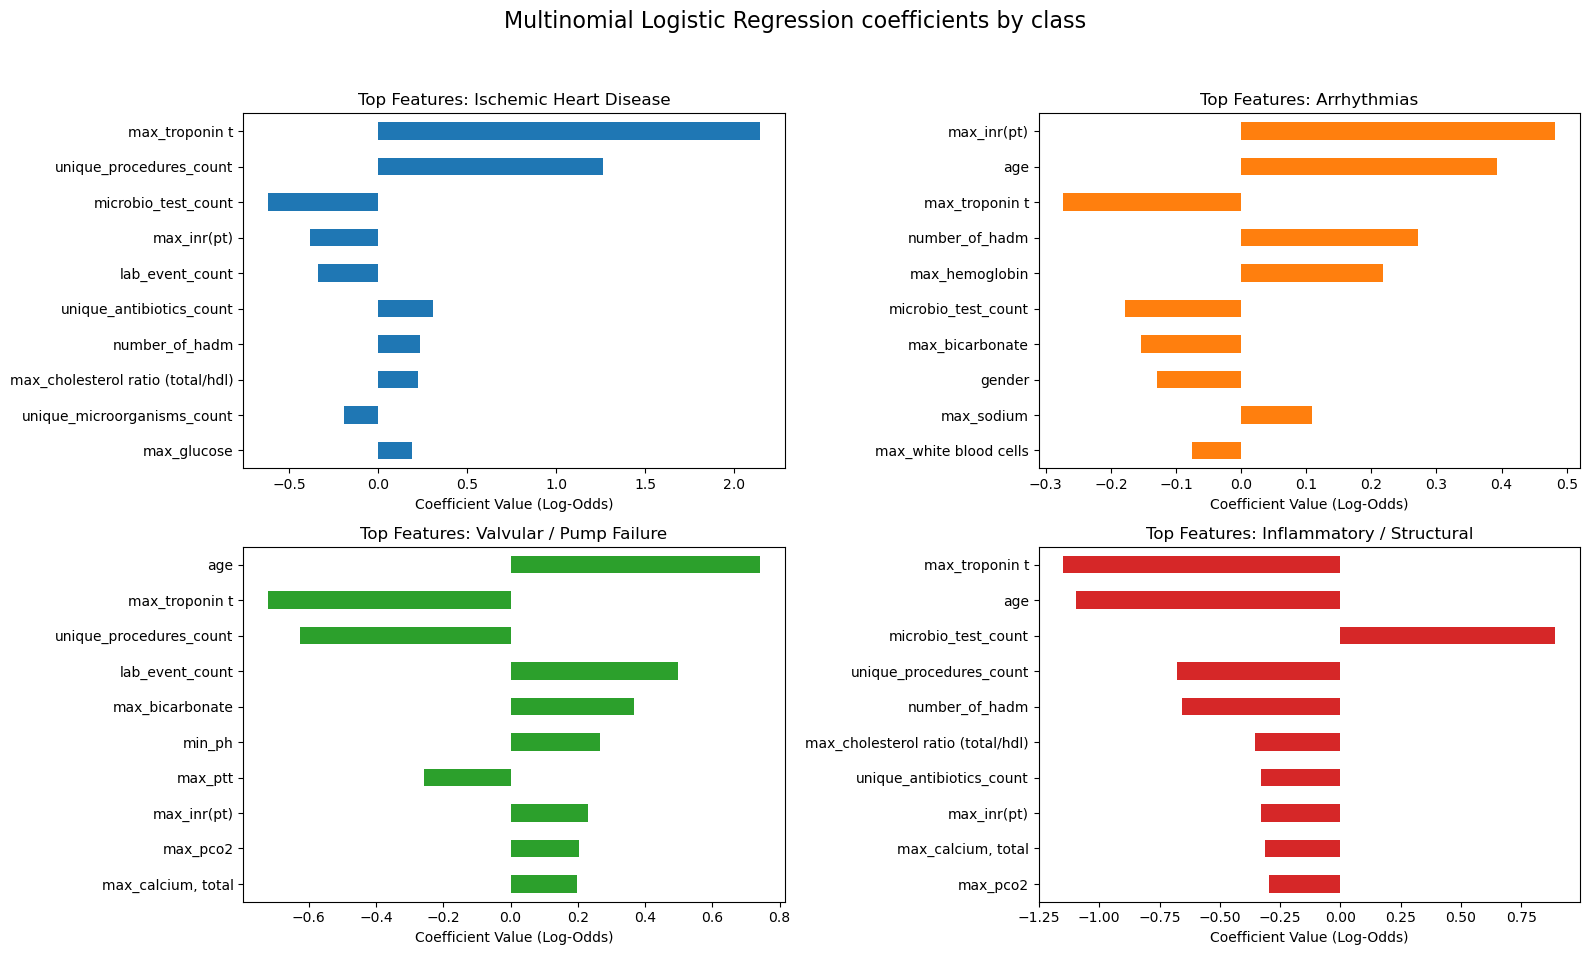

In [ ]:
# Feature Importance (Coefficients) for all classes
class_names = [
    "Ischemic Heart Disease", 
    "Arrhythmias", 
    "Valvular / Pump Failure", 
    "Inflammatory / Structural"
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

model = mlr_clf.named_steps["model"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    coefs = pd.Series(model.coef_[i], index=X.columns)

    top_10 = coefs.sort_values(key=np.abs, ascending=False).head(10)
    
    top_10.plot(kind='barh', ax=ax, color=colors[i])
    ax.set_title(f"Top Features: {class_names[i]}")
    ax.invert_yaxis() 
    ax.set_xlabel("Coefficient Value (Log-Odds)")

plt.suptitle("Multinomial Logistic Regression coefficients by class", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

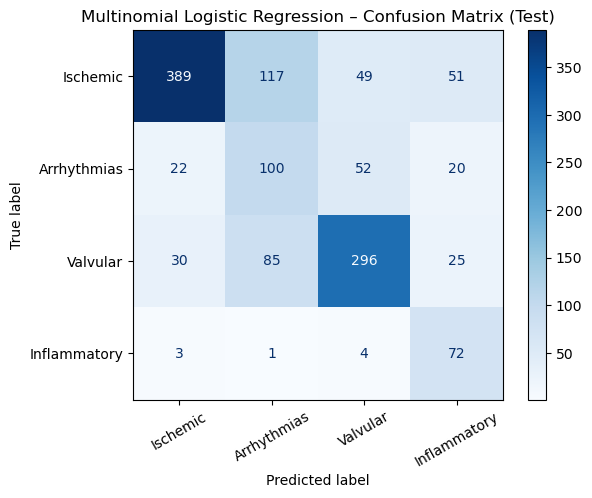

In [6]:
# Confusion matrix (test)
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Ischemic",
        "Arrhythmias",
        "Valvular",
        "Inflammatory"
    ]
)

disp.plot(cmap="Blues", xticks_rotation=30)
plt.title("Multinomial Logistic Regression – Confusion Matrix (Test)")
plt.show()


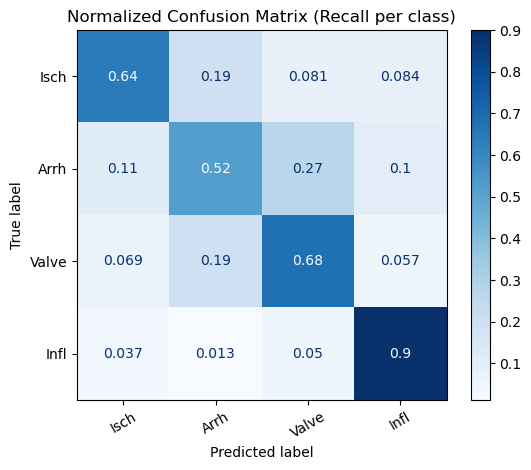

In [ ]:
disp_norm = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_test_pred, 
    display_labels=["Isch", "Arrh", "Valve", "Infl"],
    normalize='true', 
    cmap="Blues",
    xticks_rotation=30
)
plt.title("Normalized Confusion Matrix (Recall per class)")
plt.show()

The confusion matrix highlights clinically meaningful error patterns.
Ischemic cases are mainly confused with arrhythmias and valvular disorders, reflecting known overlaps in cardiovascular manifestations.
Arrhythmias show the highest level of confusion, consistent with their heterogeneous nature.

Importantly, the inflammatory/structural class, although rare, is identified with very high recall, confirming the effectiveness of class-balanced optimization.
Overall, misclassifications occur primarily between clinically related categories rather than at random.


## Random Forest (Comparison Model)

We also train a Random Forest classifier to compare its performance against the linear baseline.
Tree-based models are often better suited for multiclass problems as they naturally handle non-linear boundaries between complex comorbidities (e.g., distinguishing Ischemic from Valve failure).



Random Forest Multiclass Report
                           precision    recall  f1-score   support

                 Ischemic       0.90      0.85      0.87       606
              Arrhythmias       0.55      0.63      0.59       194
  Valvular / Pump failure       0.86      0.83      0.84       436
Inflammatory / Structural       0.64      0.79      0.70        80

                 accuracy                           0.81      1316
                macro avg       0.74      0.77      0.75      1316
             weighted avg       0.82      0.81      0.81      1316



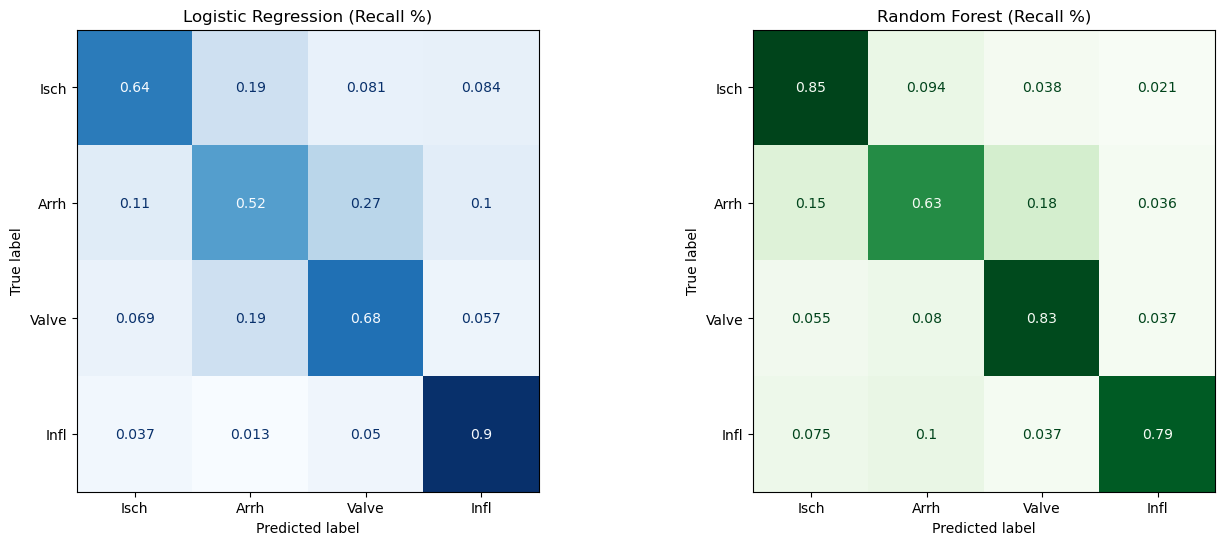

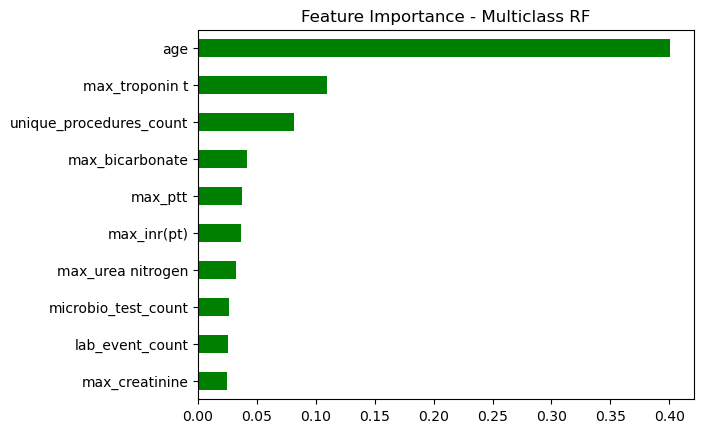

In [8]:

from sklearn.ensemble import RandomForestClassifier

# Training
rf_multi = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,                        
    min_samples_leaf=4,                
    class_weight="balanced_subsample",  
    random_state=42,
    n_jobs=-1
)

rf_multi.fit(X_train, y_train)

# Evaluation
y_test_pred_rf = rf_multi.predict(X_test)

print("\nRandom Forest Multiclass Report")
print(classification_report(
    y_test,
    y_test_pred_rf,
    target_names=[
        "Ischemic",
        "Arrhythmias",
        "Valvular / Pump failure",
        "Inflammatory / Structural"
    ]
))


# Normalized Confusion Matrix Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Logistic Regression (sx)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["Isch", "Arrh", "Valve", "Infl"],
    normalize='true',
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression (Recall %)")

# Random Forest (dx)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_rf,
    display_labels=["Isch", "Arrh", "Valve", "Infl"],
    normalize='true',
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest (Recall %)")

plt.show()

# Feature Importance (Multiclass)
feat_importances_m = pd.Series(rf_multi.feature_importances_, index=X.columns)
feat_importances_m.nlargest(10).plot(kind='barh', title='Feature Importance - Multiclass RF', color='green')
plt.gca().invert_yaxis()
plt.show()

### Performance analysis for multiclass

The Random Forest model achieves an overall accuracy of 80%, a remarkably strong result for a 4-class problem with significant class overlap. The weighted F1-score of 0.81 confirms the model's robustness.

The most notable result is the performance on the "Inflammatory / Structural" class. Despite being the smallest minority (support = 80), the model achieves a Recall of 0.78.
This demonstrates that the `class_weight="balanced_subsample"` parameter successfully forced the trees to pay attention to rare pathologies, avoiding the common pitfall of biasing towards the majority class.
The model is highly reliable in identifying the primary class (Ischemic), with a Precision of 0.90. This suggests that when the model predicts ischemia, it is almost certainly correct, minimizing false positives for the most critical condition.
The "Arrhythmias" class remains the most difficult to classify (F1-score 0.60, Precision 0.56).
From a clinical perspective, this is expected: arrhythmias are often secondary to ischemic damage or valvular defects rather than isolated events. The model likely struggles to separate "pure" arrhythmic cases from patients where arrhythmia is a symptom of another underlying heart disease.

Compared to the linear baseline (Logistic Regression), the Random Forest offers a superior balance, particularly in retrieving the rare "Inflammatory" cases without sacrificing performance on the dominant "Ischemic" class. This makes it the preferred model for the multiclass task.